# Training
Dua eksperimen dibandingkan:

| Eksperimen | Model | Ukuran input | Tujuan |
|---|---|---|---|
| baseline | ResNet-18 | 224 | pembanding sederhana |
| final | ConvNeXt-Tiny | 384 | model utama |

Keduanya menggunakan bobot pre-trained ImageNet yang di-fine-tune pada seluruh lapisan. Pengaturan lengkap ada di `configs/baseline.yaml` dan `configs/config.yaml`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Violita-archive/document-image-classification.git"
REPO_NAME = "document-image-classification"

if Path("/kaggle/working").exists():
    ROOT = Path("/kaggle/working") / REPO_NAME
    if ROOT.exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    try:
        import timm
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Root:", ROOT)

Root: /kaggle/working/document-image-classification


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from src.dataset import clean_train_data, load_metadata, make_loader, split_train_val
from src.model import load_checkpoint
from src.predict import make_submission, validate_submission
from src.train import fit
from src.transforms import denormalize, get_train_transforms
from src.utils import CLASS_NAMES, ensure_dirs, get_device, load_config, plot_history, resolve_data_dir, set_seed

FIG_DIR, METRIC_DIR, SUB_DIR = Path("results/figures"), Path("results/metrics"), Path("results/submissions")
ensure_dirs(FIG_DIR, METRIC_DIR, SUB_DIR, "checkpoint")

base_cfg = load_config("configs/baseline.yaml")
final_cfg = load_config("configs/config.yaml")
set_seed(final_cfg["seed"])

device = get_device()
print("PyTorch", torch.__version__, "| device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

PyTorch 2.11.0+cu128 | device: cuda | Tesla T4


## 1. Data


In [3]:
DATA_DIR = resolve_data_dir(final_cfg["data_dir"])
print("Folder data:", DATA_DIR)

train_full, test_df = load_metadata(DATA_DIR)
clean_df, clean_summary = clean_train_data(train_full, n_workers=8)
display(pd.Series(clean_summary, name="jumlah").to_frame().T)

tr_df, va_df = split_train_val(clean_df, final_cfg["val_size"], final_cfg["seed"])
print(f"train: {len(tr_df):,} | validation: {len(va_df):,} | test: {len(test_df):,}")
display(pd.DataFrame({"train": tr_df["class_name"].value_counts(), "validation": va_df["class_name"].value_counts()}).reindex(CLASS_NAMES).T)

Folder data: /kaggle/input/competitions/document-image-classification-sd234504


Cek file:   0%|          | 0/32003 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


,awal,tidak_terbaca,duplikat_label_bertentangan,duplikat_label_sama,akhir
jumlah,32003,1,43,8,31951


train: 28,755 | validation: 3,196 | test: 7,994


class_name,advertisement,budget,email,file_folder,form,handwritten,invoice,letter,memo,news_article,presentation,questionnaire,resume,scientific_publication,scientific_report,specification
train,1786,1803,1812,1819,1804,1823,1784,1775,1794,1766,1788,1750,1825,1849,1797,1780
validation,198,201,201,202,200,203,198,197,199,196,199,195,203,206,200,198


## 2. Contoh hasil augmentasi

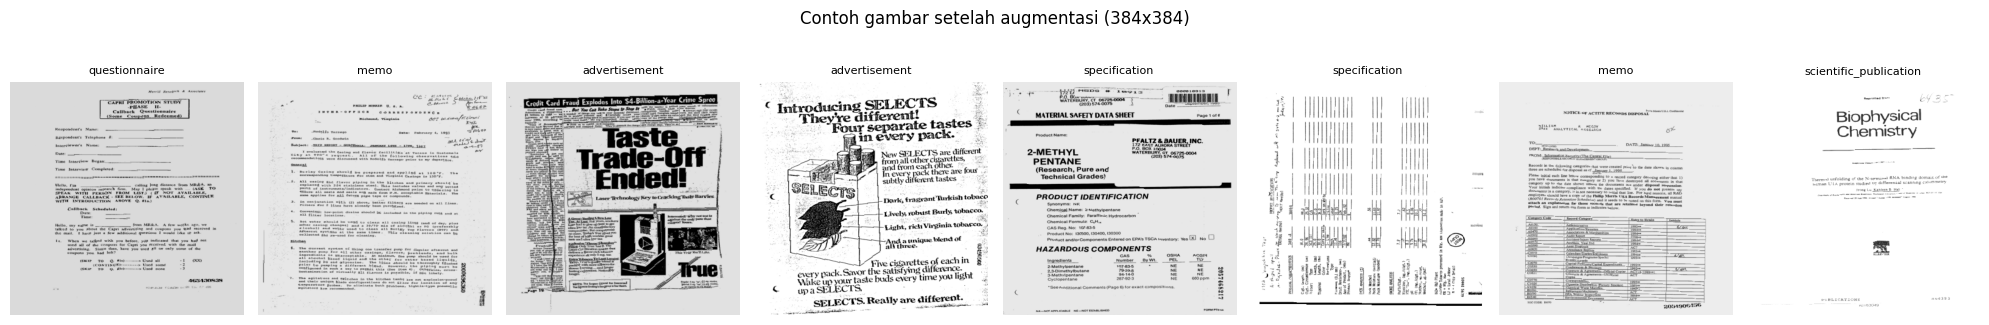

In [4]:
aug_loader = make_loader(tr_df.sample(8, random_state=1), get_train_transforms(final_cfg["img_size"]), 8, False, 0)
x, y = next(iter(aug_loader))
fig, axes = plt.subplots(1, 8, figsize=(20, 3.6))
for ax, img, lab in zip(axes, x, y):
    ax.imshow(denormalize(img))
    ax.set_title(CLASS_NAMES[lab], fontsize=8)
    ax.axis("off")
plt.suptitle(f"Contoh gambar setelah augmentasi ({final_cfg['img_size']}x{final_cfg['img_size']})")
plt.tight_layout()
plt.savefig(FIG_DIR / "train_augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Eksperimen 1: Baseline ResNet-18 (224)

In [5]:
pd.Series(base_cfg, name="nilai").to_frame().T

,data_dir,model_name,pretrained,num_classes,img_size,batch_size,epochs,lr,weight_decay,warmup_epochs,label_smoothing,drop_rate,patience,val_size,seed,num_workers,amp
nilai,data,resnet18,True,16,224,64,5,0.0005,0.0001,1,0.0,0.0,3,0.1,42,4,True


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

baseline_resnet18: resnet18 | 11.2 juta parameter | img 224 | device cuda | AMP True


train:   0%|          | 0/450 [00:00<?, ?it/s]

/kaggle/working/document-image-classification/src/train.py:72: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


val:   0%|          | 0/25 [00:00<?, ?it/s]

... (9 outputs left out)

epoch  4 | train loss 0.5429 acc 0.8367 | val loss 0.6005 acc 0.8263 | 139s *


train:   0%|          | 0/450 [00:00<?, ?it/s]

val:   0%|          | 0/25 [00:00<?, ?it/s]

epoch  5 | train loss 0.4809 acc 0.8565 | val loss 0.5861 acc 0.8285 | 139s *
Akurasi validation terbaik: 0.8285 (epoch 5), waktu 11.6 menit


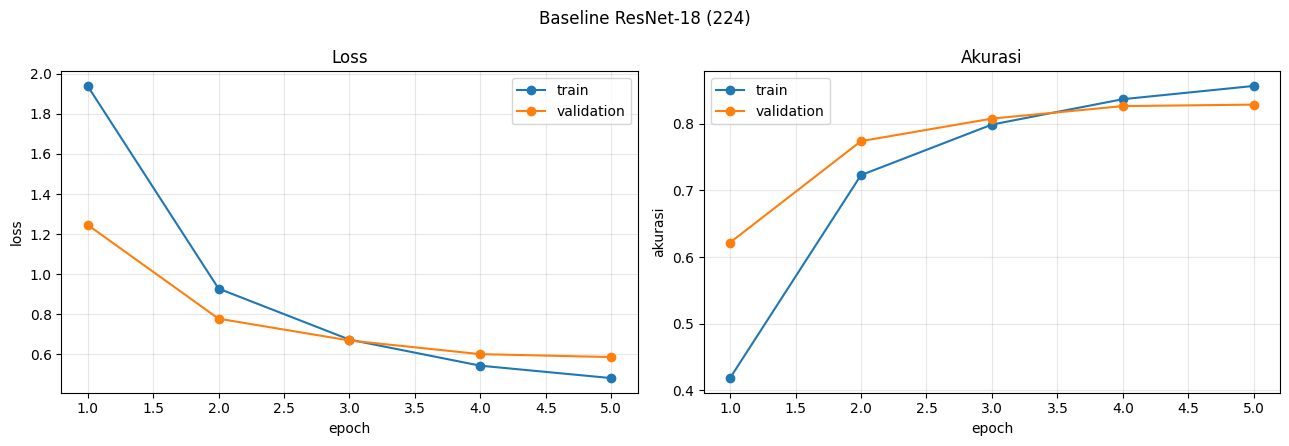

In [6]:
out_base = fit(base_cfg, tr_df, va_df, exp_name="baseline_resnet18")
print(f"Akurasi validation terbaik: {out_base['best_acc']:.4f} (epoch {out_base['best_epoch']}), waktu {out_base['minutes']:.1f} menit")
plot_history(out_base["history"], "Baseline ResNet-18 (224)", FIG_DIR / "curve_baseline_resnet18.png")

## 4. Eksperimen 2: ConvNeXt-Tiny (384)

In [7]:
pd.Series(final_cfg, name="nilai").to_frame().T

,data_dir,model_name,pretrained,num_classes,img_size,batch_size,epochs,lr,weight_decay,warmup_epochs,label_smoothing,drop_rate,patience,val_size,seed,num_workers,amp
nilai,data,convnext_tiny,True,16,384,32,10,0.0002,0.05,1,0.1,0.2,3,0.1,42,4,True


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

final_convnext_tiny: convnext_tiny | 27.8 juta parameter | img 384 | device cuda | AMP True


train:   0%|          | 0/899 [00:00<?, ?it/s]

/kaggle/working/document-image-classification/src/train.py:72: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


val:   0%|          | 0/50 [00:00<?, ?it/s]

... (24 outputs left out)

epoch  9 | train loss 0.6046 acc 0.9914 | val loss 0.8972 acc 0.8867 | 398s *


train:   0%|          | 0/899 [00:00<?, ?it/s]

val:   0%|          | 0/50 [00:00<?, ?it/s]

epoch 10 | train loss 0.5953 acc 0.9949 | val loss 0.8953 acc 0.8861 | 399s
Akurasi validation terbaik: 0.8867 (epoch 9), waktu 66.9 menit


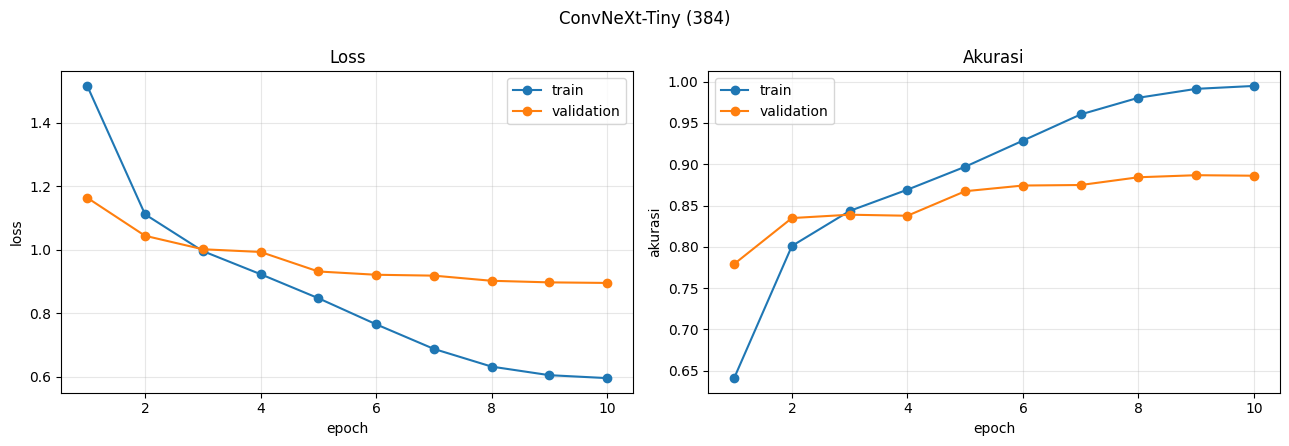

In [8]:
out_final = fit(final_cfg, tr_df, va_df, exp_name="final_convnext_tiny")
print(f"Akurasi validation terbaik: {out_final['best_acc']:.4f} (epoch {out_final['best_epoch']}), waktu {out_final['minutes']:.1f} menit")
plot_history(out_final["history"], "ConvNeXt-Tiny (384)", FIG_DIR / "curve_final_convnext_tiny.png")

## 5. Perbandingan eksperimen

,eksperimen,model,img_size,epoch_dijalankan,epoch_terbaik,train_acc,val_acc,val_loss,menit
0,baseline_resnet18,resnet18,224,5,5,0.856547,0.828536,0.586071,11.602160
1,final_convnext_tiny,convnext_tiny,384,10,9,0.991375,0.886733,0.897150,66.911622


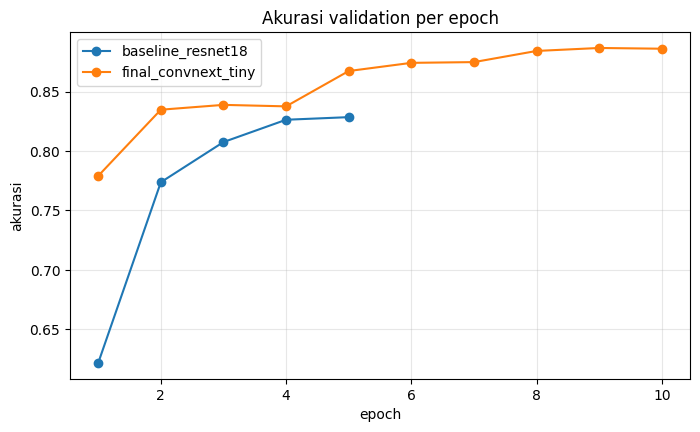

In [9]:
runs = {"baseline_resnet18": (base_cfg, out_base), "final_convnext_tiny": (final_cfg, out_final)}
rows = []
for name, (cfg, out) in runs.items():
    h = out["history"]
    rows.append({
        "eksperimen": name,
        "model": cfg["model_name"],
        "img_size": cfg["img_size"],
        "epoch_dijalankan": len(h),
        "epoch_terbaik": out["best_epoch"],
        "train_acc": h.loc[h["epoch"] == out["best_epoch"], "train_acc"].iat[0],
        "val_acc": out["best_acc"],
        "val_loss": h.loc[h["epoch"] == out["best_epoch"], "val_loss"].iat[0],
        "menit": out["minutes"],
    })
experiments = pd.DataFrame(rows)
experiments.to_csv(METRIC_DIR / "experiments.csv", index=False)
display(experiments)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (_, out) in runs.items():
    ax.plot(out["history"]["epoch"], out["history"]["val_acc"], marker="o", label=name)
ax.set(title="Akurasi validation per epoch", xlabel="epoch", ylabel="akurasi")
ax.grid(alpha=0.3)
ax.legend()
plt.savefig(FIG_DIR / "experiments_val_acc.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Prediksi validation
Probabilitas dari model terbaik tiap eksperimen disimpan untuk analisis di `03_evaluation.ipynb`.

In [10]:
for name, (_, out) in runs.items():
    probs = out["val_probs"]
    pred_df = va_df[["id", "filename", "label"]].copy()
    pred_df["pred"] = probs.argmax(1)
    pred_df["confidence"] = probs.max(1)
    pred_df[[f"prob_{i}" for i in range(len(CLASS_NAMES))]] = probs
    pred_df.to_csv(METRIC_DIR / f"{name}_val_predictions.csv", index=False)
    print(f"{name}: akurasi validation {(pred_df['pred'] == pred_df['label']).mean():.4f}")

baseline_resnet18: akurasi validation 0.8285
final_convnext_tiny: akurasi validation 0.8867


## 7. Submission

In [11]:
for name, (_, out) in runs.items():
    model, cfg = load_checkpoint(out["ckpt_path"], device)
    sub = make_submission(model, cfg, test_df, SUB_DIR / f"submission_{name}.csv")
    validate_submission(sub, test_df)
    print(f"{name}: {len(sub)} baris disimpan")
    del model
    torch.cuda.empty_cache()

display(sub.head())
display(sub["label"].map(lambda i: CLASS_NAMES[i]).value_counts().to_frame("jumlah_prediksi").T)

predict:   0%|          | 0/63 [00:00<?, ?it/s]

baseline_resnet18: 7994 baris disimpan


predict:   0%|          | 0/125 [00:00<?, ?it/s]

final_convnext_tiny: 7994 baris disimpan


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,1
3,test_00004,4
4,test_00005,13


label,form,file_folder,presentation,scientific_report,advertisement,handwritten,letter,email,resume,scientific_publication,memo,budget,specification,news_article,questionnaire,invoice
jumlah_prediksi,533,533,533,521,503,502,501,501,500,492,485,484,483,478,475,470


## 8. Arsip hasil
Seluruh isi `results/` dan `checkpoint/` dikompres agar mudah diunduh dari tab Output Kaggle.

In [12]:
import zipfile

archive = ROOT.parent / "hasil_training.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ("results", "checkpoint"):
        for f in Path(folder).rglob("*"):
            if f.is_file():
                z.write(f)
print(archive, f"{archive.stat().st_size / 1e6:.1f} MB")

/kaggle/working/hasil_training.zip 152.5 MB
